# STATE — Chemical similarity to training drugs

Chemical similarity describes how closely a test drug’s molecular structure resembles a drug used in training. The audit placed drugs into five similarity groups and compared how well STATE recovered the genes that responded to each drug.

Run the six sections in order. Every custom calculation is written in these cells; no external analysis scripts or saved derived tables are required. The analysis uses official STATE released evaluation scores for the HVG and SE representations. The audit does not fine-tune STATE or run fresh inference.

Use Python 3.11 with `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 rdkit==2025.3.6 ipython ipykernel`. An existing raw-data cache can be selected with `STATE_PRIMARY_INPUTS`; each input is checked against its declared SHA256 before reuse.


## 1. Data source/acquisition

The source table specifies pinned score downloads, split definitions, and annotation inputs. Annotation files are distributed in a versioned public data package; their upstream providers are listed alongside the package URL. Only raw annotations are read from that package.


In [1]:
ANALYSIS_ID="state-featured/test-01"
TITLE='Chemical similarity to training drugs'

from pathlib import Path
import ast, csv, gzip, hashlib, io, json, math, os, re, shutil, tarfile, time, tomllib, urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
STARTED=time.time()
INPUTS=Path(os.environ.get('STATE_PRIMARY_INPUTS','state_primary_inputs')).resolve()
OUTPUTS=Path('state_primary_outputs')/ANALYSIS_ID.split('/')[-1]
INPUTS.mkdir(parents=True,exist_ok=True)
OUTPUTS.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)


In [2]:
SOURCES=[{'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 276570,
  'sha256': 'ca5377b00f6700bee2b4b17eeaf4e703fc2d3797ac8271c2f282088fcbb289e8'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269473,
  'sha256': '489cbe64636b7765fe7f24fe5536da9fb1ee86226effd9eeb422634d5731396b'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 284828,
  'sha256': '49e3ce723ec7ca6bfc044d438902129ffb9ec2682d33a73e16693735c4746ad4'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 275993,
  'sha256': 'f391f46e60061332b2a555567443aeb3190239c4bdac146bcb3340d503aeebe9'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 272057,
  'sha256': '2654fe5b526d577807a63b30a9c85a70d829979afe452325650071a3f22a03ae'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03'},
 {'kind': 'drug_metadata',
  'path': 'metadata/drug_metadata.parquet',
  'url': 'https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b006546a95/metadata/drug_metadata.parquet',
  'bytes': 40475,
  'sha256': '7a04c7a6611e74c92253163b994ff0a47191928ee7511f1c2ca508cee0e79f28'},
 {'kind': 'split',
  'path': 'splits/tahoe_tomls/generalization.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/tahoe_tomls/generalization.toml',
  'bytes': 150875,
  'sha256': 'eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783'}]
ANNOTATIONS=[]
ANNOTATION_PACKAGE={'path': 'annotations.tar.gz', 'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/payloads/state-historical-annotations.tar.gz', 'bytes': 40411527, 'sha256': 'ddba844c5803aeb2e32c51f72889b16fc77efa13f1ace9ba541508f4ed31c059'}


In [3]:
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8<<20),b''):h.update(block)
    return h.hexdigest()

def verified(path,entry):
    return path.is_file() and path.stat().st_size==entry['bytes'] and sha256_file(path)==entry['sha256']

def download(entry):
    path=INPUTS/entry['path']
    if verified(path,entry):return path
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            request=urllib.request.Request(entry['url'],headers={'User-Agent':'SPECTRA-notebook/1.0'})
            with urllib.request.urlopen(request,timeout=120) as response, temporary.open('wb') as f:
                shutil.copyfileobj(response,f,8<<20)
            if not verified(temporary,entry):raise ValueError('Download checksum mismatch: '+entry['path'])
            temporary.replace(path)
            return path
        except Exception:
            if attempt==3:raise
            time.sleep(2**attempt)

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded=list(pool.map(download,SOURCES))
if ANNOTATIONS:
    missing=[s for s in ANNOTATIONS if not verified(INPUTS/s['path'],s)]
    if missing:
        archive_path=download(ANNOTATION_PACKAGE)
        with tarfile.open(archive_path) as archive:
            for entry in missing:
                path=INPUTS/entry['path'];path.parent.mkdir(parents=True,exist_ok=True)
                with archive.extractfile(entry['member']) as source,path.open('wb') as destination:
                    shutil.copyfileobj(source,destination)
                assert verified(path,entry),entry['path']
    assert all(verified(INPUTS/s['path'],s) for s in ANNOTATIONS)
source_receipts=[{'path':s['path'],'url':s['url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in SOURCES]
source_receipts += [{'path':s['path'],'url':ANNOTATION_PACKAGE['url'],'source_url':s['source_url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in ANNOTATIONS]
display(pd.DataFrame(source_receipts)[['path','bytes','url']])
print('Verified source files:',len(source_receipts))


,path,bytes,url
0,scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,276570,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
1,scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv,269473,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
2,scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv,284828,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
3,scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv,275993,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
4,scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv,272057,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
5,scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv,468117,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
6,scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv,459434,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
7,scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_result...,479496,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
8,scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv,466949,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
9,scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv,461203,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...


Verified source files: 22


## 2. Data processing

Parse the released condition identifiers and source filenames, retain the context/protocol/representation labels, and read the prospective annotation or chemical features. Metric values remain the official released scores.


In [4]:
def i_norm_name(x: str) -> str:
    x = str(x).strip().lower()
    x = re.sub('\\s+', ' ', x)
    return x

def i_loose_name(x: str) -> str:
    x = i_norm_name(x)
    x = re.sub('\\([^)]*\\)', '', x)
    x = re.sub('\\b(hydrochloride|hydrate|monohydrate|dihydrate|trihydrate|mesylate|maleate|tosylate|sodium|calcium|potassium|phosphate|sulfate|citrate|acetate|hemihydrate|salt|solvate|tf)\\b', '', x)
    x = re.sub('[^a-z0-9]+', '', x)
    return x

def i_parse_perturbation(value: str):
    """Parse STATE perturbation strings into name/dose/unit when possible."""
    if not isinstance(value, str):
        return (None, np.nan, None)
    s = value.strip()
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, list) and obj and isinstance(obj[0], tuple):
            tup = obj[0]
            name = str(tup[0]).strip()
            dose = float(tup[1]) if len(tup) > 1 else np.nan
            unit = str(tup[2]) if len(tup) > 2 else None
            return (name, dose, unit)
    except Exception:
        pass
    return (s, np.nan, None)

def i_parse_result_path(repo: str, path: str):
    dataset = 'unknown'
    protocol = 'unknown'
    context = None
    split_id = None
    representation = 'SE' if 'ST-SE' in repo else 'HVG'
    if 'Tahoe' in repo:
        dataset = 'Tahoe-100M'
        protocol = 'zeroshot' if path.startswith('zeroshot/') else 'fewshot'
        context = Path(path).name.replace('_results.csv', '')
    elif 'Replogle' in repo:
        dataset = 'Replogle-Nadig'
        parts = path.split('/')
        protocol = parts[0]
        context = parts[1]
    elif 'Parse' in repo:
        dataset = 'Parse-PBMC'
        parts = path.split('/')
        protocol = parts[0]
        split_id = parts[1]
        context = Path(path).name.replace('_results.csv', '')
    return (dataset, protocol, context, split_id, representation)

frames=[]
for source in SOURCES:
    if source['kind']!='released_score':continue
    frame=pd.read_csv(INPUTS/source['path'])
    dataset,protocol,context,split_id,representation=i_parse_result_path(source['repo'],source['filename'])
    for name,value in [('source_repo',source['repo']),('source_path',source['filename']),('dataset_family',dataset),('protocol',protocol),('context',context),('split_id',split_id),('representation',representation)]:frame[name]=value
    parsed=[i_parse_perturbation(x) for x in frame.perturbation]
    frame['perturbation_name']=[x[0] for x in parsed]
    frame['dose']=[x[1] for x in parsed]
    frame['dose_unit']=[x[2] for x in parsed]
    frame['perturbation_norm']=frame.perturbation_name.map(i_norm_name)
    frame['perturbation_loose']=frame.perturbation_name.map(i_loose_name)
    frames.append(frame)
results=pd.concat(frames,ignore_index=True)
results['row_key']=np.arange(len(results)).astype(str)
for metric in ['overlap_at_N','de_sig_genes_recall','pearson_delta']:
    results[metric]=pd.to_numeric(results[metric],errors='coerce')
display(results.groupby(['protocol','representation','context']).size().rename('released_rows').reset_index())


,protocol,representation,context,released_rows
0,fewshot,HVG,C32,735
1,fewshot,HVG,HOP62,735
2,fewshot,HVG,HepG2-C3A,735
3,fewshot,HVG,Hs 766T,735
4,fewshot,HVG,PANC-1,734
5,fewshot,SE,C32,735
6,fewshot,SE,HOP62,735
7,fewshot,SE,HepG2-C3A,735
8,fewshot,SE,Hs 766T,735
9,fewshot,SE,PANC-1,734


In [5]:
def i_make_drug_lookup(drug_meta: pd.DataFrame):
    by_norm = {}
    by_loose = {}
    for _, row in drug_meta.iterrows():
        rec = row.to_dict()
        n = i_norm_name(row['drug'])
        l = i_loose_name(row['drug'])
        by_norm.setdefault(n, rec)
        by_loose.setdefault(l, rec)
    return (by_norm, by_loose)

def i_attach_drug_metadata(df: pd.DataFrame, drug_meta: pd.DataFrame):
    by_norm, by_loose = i_make_drug_lookup(drug_meta)
    recs = []
    map_status = []
    for _, row in df.iterrows():
        rec = by_norm.get(row['perturbation_norm'])
        status = 'exact_norm'
        if rec is None:
            rec = by_loose.get(row['perturbation_loose'])
            status = 'loose'
        if rec is None:
            rec = {}
            status = 'missing'
        map_status.append(status)
        recs.append(rec)
    meta = pd.DataFrame(recs)
    meta = meta.add_prefix('drugmeta_')
    out = pd.concat([df.reset_index(drop=True), meta.reset_index(drop=True)], axis=1)
    out['drug_metadata_match'] = map_status
    return out

def i_canonical_context_name(x: str) -> str:
    return str(x).strip().replace('/', '-')

def i_parse_toml(path: Path):
    with open(path, 'rb') as f:
        return tomllib.load(f)

def i_parse_tahoe_fewshot_toml(path: Path):
    cfg = i_parse_toml(path)
    out = {}
    for key, spec in cfg.get('fewshot', {}).items():
        context = i_canonical_context_name(key.split('.', 1)[1])
        parsed = {'val': [], 'test': []}
        for split in ['val', 'test']:
            for p in spec.get(split, []):
                name, dose, unit = i_parse_perturbation(p)
                parsed[split].append({'perturbation': p, 'drug': name, 'dose': dose, 'unit': unit, 'drug_norm': i_norm_name(name), 'drug_loose': i_loose_name(name)})
        out[context] = parsed
    return out

drug_metadata=pd.read_parquet(INPUTS/'metadata/drug_metadata.parquet')
results=i_attach_drug_metadata(results,drug_metadata)
i_STATE=INPUTS
# Split folder follows the public STATE layout.


## 3. Axis definition and level construction


Compute a radius-2, 2,048-bit Morgan fingerprint for each drug. For each target context, the training-reference drugs are the metadata drug universe minus the validation and test drugs listed in its split. The axis is the maximum Tanimoto similarity to those training-reference drugs. Five equal-frequency bins are assigned from similarity ranks before grouping the outcomes.


In [6]:
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
def i_fingerprint_from_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    return gen.GetFingerprint(mol)

def i_is_fingerprint(value) -> bool:
    return value is not None and hasattr(value, 'GetNumBits')

def i_compute_context_chemical_axis(tahoe_df: pd.DataFrame, drug_meta: pd.DataFrame):
    toml_path = INPUTS / 'splits' / 'tahoe_tomls' / 'generalization.toml'
    fewshot = i_parse_tahoe_fewshot_toml(toml_path)
    by_norm, by_loose = i_make_drug_lookup(drug_meta)
    drug_meta = drug_meta.copy()
    drug_meta['drug_norm'] = drug_meta['drug'].map(i_norm_name)
    drug_meta['drug_loose'] = drug_meta['drug'].map(i_loose_name)
    drug_meta['fingerprint'] = drug_meta['canonical_smiles'].map(i_fingerprint_from_smiles)
    fps_by_norm = {r['drug_norm']: r['fingerprint'] for _, r in drug_meta.iterrows() if i_is_fingerprint(r['fingerprint'])}
    fps_by_loose = {r['drug_loose']: r['fingerprint'] for _, r in drug_meta.iterrows() if i_is_fingerprint(r['fingerprint'])}

    def find_fp(norm, loose):
        fp = fps_by_norm.get(norm)
        if i_is_fingerprint(fp):
            return fp
        fp = fps_by_loose.get(loose)
        if i_is_fingerprint(fp):
            return fp
        return None
    all_drugs = set(drug_meta['drug_norm'])
    context_train = {}
    context_val = {}
    context_test = {}
    for context, spec in fewshot.items():
        val = {x['drug_norm'] for x in spec['val']}
        test = {x['drug_norm'] for x in spec['test']}
        context_val[context] = val
        context_test[context] = test
        context_train[context] = all_drugs - val - test
    sim_records = []
    for context, train_norms in context_train.items():
        train_fps = []
        for n in train_norms:
            rec = by_norm.get(n)
            if rec is None:
                continue
            fp = i_fingerprint_from_smiles(rec.get('canonical_smiles'))
            if fp is not None:
                train_fps.append((n, rec.get('drug'), fp))
        for _, row in tahoe_df[tahoe_df['context'] == context].iterrows():
            fp = find_fp(row['perturbation_norm'], row['perturbation_loose'])
            max_sim = np.nan
            nearest = None
            if i_is_fingerprint(fp) and train_fps:
                sims = [(DataStructs.TanimotoSimilarity(fp, tfp), n, d) for n, d, tfp in train_fps]
                max_sim, _, nearest = max(sims, key=lambda x: x[0])
            sim_records.append({'row_key': row['row_key'], 'target_context_train_drug_count': len(train_norms), 'target_context_val_drug_count': len(context_val[context]), 'target_context_test_drug_count': len(context_test[context]), 'max_tanimoto_to_target_context_train_drug': max_sim, 'nearest_target_context_train_drug': nearest})
    sim_df = pd.DataFrame(sim_records)
    out = tahoe_df.merge(sim_df, on='row_key', how='left')
    eligible = out[(out['dataset_family'] == 'Tahoe-100M') & (out['protocol'] == 'fewshot') & out['max_tanimoto_to_target_context_train_drug'].notna()].copy()
    labels = ['L5_far', 'L4_low_mid', 'L3_mid', 'L2_high_mid', 'L1_near']
    eligible['chem_support_level'] = pd.qcut(eligible['max_tanimoto_to_target_context_train_drug'].rank(method='first'), q=5, labels=labels)
    level_map = eligible[['row_key', 'chem_support_level']]
    out = out.merge(level_map, on='row_key', how='left')
    return out

examples=i_compute_context_chemical_axis(results,drug_metadata)
examples=examples[(examples.protocol=='fewshot') & examples.chem_support_level.notna()].copy()
FEATURE='max_tanimoto_to_target_context_train_drug'
LEVEL='chem_support_level'
display(examples.groupby(LEVEL,observed=True)[FEATURE].agg(['count','min','mean','max']))


,count,min,mean,max
chem_support_level,,,,
L5_far,1458,0.061224,0.156639,0.178571
L4_low_mid,1457,0.178571,0.193175,0.207207
L3_mid,1458,0.207207,0.219604,0.233766
L2_high_mid,1457,0.233766,0.251312,0.272727
L1_near,1458,0.272727,0.411229,0.983607


## 4. Model results or released scores

Each condition is evaluated using the official `eval_best.ckpt` result file named in section 1. `overlap_at_N` is the primary score; `de_sig_genes_recall` and `pearson_delta` are secondary scores. HVG and SE are kept separate. No audit-specific model fine-tuning is performed.


In [7]:
assert examples.row_key.notna().all()
assert 'overlap_at_N' in examples
score_columns=['source_repo','source_path','context','representation','perturbation','overlap_at_N','de_sig_genes_recall','pearson_delta']
display(examples[score_columns].head(10))
display(examples.groupby(['protocol','representation']).agg(rows=('row_key','size'),valid_overlap=('overlap_at_N','count')))


,source_repo,source_path,context,representation,perturbation,overlap_at_N,de_sig_genes_recall,pearson_delta
0,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",0.406250,0.687500,0.953422
1,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",0.570093,0.742991,0.941397
2,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",0.534709,0.748593,0.957216
3,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(S)-Crizotinib', 0.05, 'uM')]",0.669829,0.863378,0.980804
4,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(S)-Crizotinib', 0.5, 'uM')]",0.441441,0.576577,0.891409
5,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('(S)-Crizotinib', 5.0, 'uM')]",0.508834,0.795053,0.945581
6,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('5-Fluorouracil', 0.05, 'uM')]",0.573209,0.813084,0.959948
7,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('5-Fluorouracil', 0.5, 'uM')]",0.611111,0.891111,0.982484
8,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('8-Hydroxyquinoline', 0.05, 'uM')]",0.462069,0.496552,0.852296
9,arcinstitute/ST-HVG-Tahoe,fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv,C32,HVG,"[('8-Hydroxyquinoline', 0.5, 'uM')]",0.373259,0.674095,0.933624


rows  valid_overlap
protocol representation                     
fewshot  HVG             3644           3644
         SE              3644           3644

## 5. Curves and controls

Calculate per-level means from the individual condition rows. The plots keep each representation and discovery/confirmation subset separate. Controls and contrasts below are calculated from the same rows. Higher overlap@N indicates better prediction.


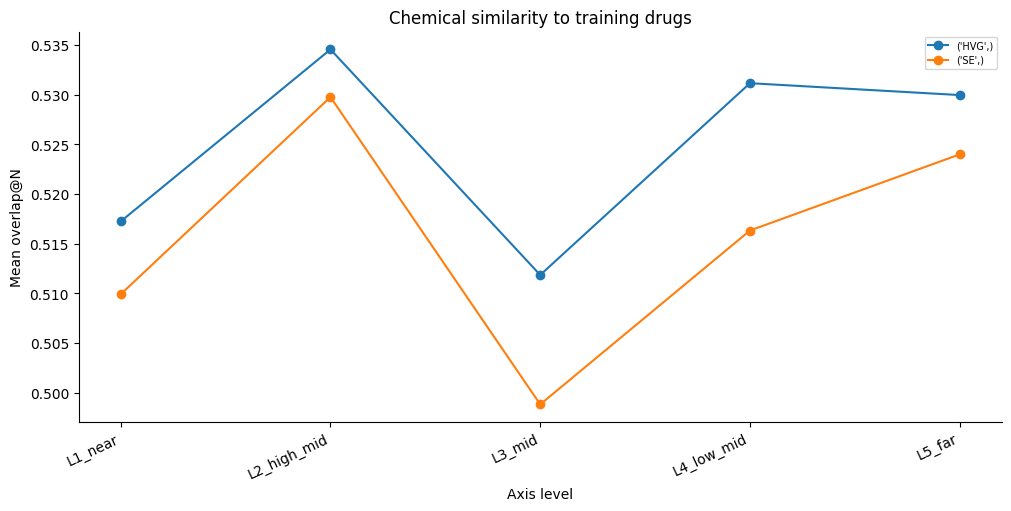

,subset,axis_col,level,n_rows,n_unique_contexts,n_unique_perturbations,n_unique_drug_context_dose,similarity_mean,similarity_min,similarity_max,...,de_spearman_lfc_sig_median,de_spearman_lfc_sig_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std,mse_delta_mean,mse_delta_median,mse_delta_std,state_de_count_mae,representation
0,Chemical similarity to training drugs,chem_support_level,L1_near,720,5,52,720,0.412960,0.275362,0.983607,...,0.633797,0.145957,0.932590,0.940722,0.039627,0.000207,0.000131,0.000289,139.461111,HVG
1,Chemical similarity to training drugs,chem_support_level,L2_high_mid,735,5,54,735,0.251634,0.233766,0.272727,...,0.609368,0.143474,0.924882,0.935769,0.048270,0.000267,0.000145,0.000453,137.333333,HVG
2,Chemical similarity to training drugs,chem_support_level,L3_mid,729,5,54,729,0.219696,0.207317,0.233766,...,0.631267,0.204377,0.910345,0.935163,0.120266,0.001064,0.000175,0.007772,144.046639,HVG
3,Chemical similarity to training drugs,chem_support_level,L4_low_mid,730,5,54,730,0.193243,0.178947,0.207207,...,0.631886,0.151790,0.921532,0.934742,0.069185,0.000478,0.000157,0.001266,135.506849,HVG
4,Chemical similarity to training drugs,chem_support_level,L5_far,730,5,53,730,0.156669,0.061224,0.178571,...,0.610721,0.134038,0.930169,0.937499,0.039078,0.000287,0.000140,0.000791,129.352055,HVG
5,Chemical similarity to training drugs,chem_support_level,L1_near,738,5,54,738,0.409540,0.272727,0.983607,...,0.602870,0.144896,0.921963,0.932654,0.046957,0.000234,0.000155,0.000314,135.898374,SE
6,Chemical similarity to training drugs,chem_support_level,L2_high_mid,722,5,54,722,0.250984,0.233766,0.272727,...,0.594709,0.144098,0.917579,0.929579,0.049767,0.000288,0.000175,0.000447,135.997230,SE
7,Chemical similarity to training drugs,chem_support_level,L3_mid,729,5,54,729,0.219513,0.207207,0.233333,...,0.614407,0.202785,0.900015,0.926659,0.122471,0.001095,0.000208,0.007972,149.677641,SE
8,Chemical similarity to training drugs,chem_support_level,L4_low_mid,727,5,55,727,0.193107,0.178571,0.207207,...,0.614462,0.156608,0.912723,0.928708,0.070244,0.000510,0.000188,0.001263,138.261348,SE
9,Chemical similarity to training drugs,chem_support_level,L5_far,728,5,53,728,0.156609,0.061224,0.178571,...,0.594324,0.143727,0.920029,0.927085,0.043377,0.000320,0.000168,0.000820,131.315934,SE


,representation,metric,pearson_level_corr_with_similarity,near_mean,far_mean,far_minus_near,relative_far_minus_near
0,HVG,overlap_at_N,-0.426254,0.517249,0.529965,0.012715,0.024583
1,HVG,de_sig_genes_recall,0.186078,0.700895,0.696062,-0.004833,-0.006895
2,HVG,de_spearman_lfc_sig,0.706174,0.613223,0.598088,-0.015135,-0.024681
3,HVG,pearson_delta,0.397606,0.932590,0.930169,-0.002421,-0.002596
4,HVG,mse_delta,-0.320146,0.000207,0.000287,0.000080,0.386810
5,SE,overlap_at_N,-0.254446,0.509921,0.523998,0.014077,0.027605
6,SE,de_sig_genes_recall,-0.185095,0.676044,0.677499,0.001456,0.002153
7,SE,de_spearman_lfc_sig,0.394418,0.585225,0.577457,-0.007768,-0.013274
8,SE,pearson_delta,0.354757,0.921963,0.920029,-0.001934,-0.002097
9,SE,mse_delta,-0.322857,0.000234,0.000320,0.000086,0.366583


In [8]:
i_PRIMARY_METRICS=['overlap_at_N','de_sig_genes_recall','de_spearman_lfc_sig','pearson_delta','mse_delta']
def i_summarize_axis(df: pd.DataFrame, axis_col: str, similarity_col: str, subset_name: str):
    rows = []
    sub = df[df[axis_col].notna()].copy()
    order = sorted(sub[axis_col].unique())
    for level in order:
        g = sub[sub[axis_col] == level]
        rec = {'subset': subset_name, 'axis_col': axis_col, 'level': str(level), 'n_rows': int(len(g)), 'n_unique_contexts': int(g['context'].nunique()), 'n_unique_perturbations': int(g['perturbation_name'].nunique()), 'n_unique_drug_context_dose': int(g[['context', 'perturbation_name', 'dose']].drop_duplicates().shape[0]), 'similarity_mean': float(g[similarity_col].mean()), 'similarity_min': float(g[similarity_col].min()), 'similarity_max': float(g[similarity_col].max()), 'zero_de_baseline_overlap_at_N': 0.0, 'zero_de_baseline_de_sig_genes_recall': 0.0, 'zero_de_baseline_de_count_mae': float(g['de_nsig_counts_real'].abs().mean())}
        for m in i_PRIMARY_METRICS:
            if m in g.columns:
                rec[f'{m}_mean'] = float(g[m].mean())
                rec[f'{m}_median'] = float(g[m].median())
                rec[f'{m}_std'] = float(g[m].std(ddof=1))
        if 'de_nsig_counts_pred' in g.columns:
            rec['state_de_count_mae'] = float((g['de_nsig_counts_pred'] - g['de_nsig_counts_real']).abs().mean())
        rows.append(rec)
    return pd.DataFrame(rows)

def i_metric_trend(summary: pd.DataFrame, metric: str):
    s = summary[['level', 'similarity_mean', f'{metric}_mean']].copy()
    if len(s) < 3 or s[f'{metric}_mean'].isna().any():
        return {'metric': metric, 'status': 'insufficient'}
    s = s.sort_values('similarity_mean', ascending=False)
    x = s['similarity_mean'].to_numpy()
    y = s[f'{metric}_mean'].to_numpy()
    if len(np.unique(x)) < 3:
        return {'metric': metric, 'status': 'invalid_similarity_degenerate'}
    corr = float(np.corrcoef(x, y)[0, 1])
    near = float(y[0])
    far = float(y[-1])
    delta_far_minus_near = far - near
    return {'metric': metric, 'pearson_level_corr_with_similarity': corr, 'near_mean': near, 'far_mean': far, 'far_minus_near': delta_far_minus_near, 'relative_far_minus_near': float(delta_far_minus_near / near) if near else np.nan}

curves=[];trend_rows=[]
for representation,part in examples.groupby('representation'):
    table=i_summarize_axis(part,LEVEL,FEATURE,TITLE)
    table['representation']=representation
    curves.append(table)
    for metric in i_PRIMARY_METRICS:
        trend_rows.append({'representation':representation,**i_metric_trend(table,metric)})
curve=pd.concat(curves,ignore_index=True)
trends=pd.DataFrame(trend_rows)

def plot_curve(table,title):
    figure,axis=plt.subplots(figsize=(10,5),layout='constrained')
    group_cols=[x for x in ['spectra_subset','representation'] if x in table]
    order=sorted(table.level.astype(str).unique())
    xmap={value:i for i,value in enumerate(order)}
    groups=table.groupby(group_cols,dropna=False) if group_cols else [('STATE',table)]
    for name,part in groups:
        part=part.copy();part['x']=part.level.astype(str).map(xmap);part=part.sort_values('x')
        axis.plot(part.x,part.overlap_at_N_mean,marker='o',label=str(name))
    axis.set_xticks(range(len(order)),order,rotation=25,ha='right')
    axis.set(xlabel='Axis level',ylabel='Mean overlap@N',title=title)
    axis.legend(fontsize=7);axis.spines[['top','right']].set_visible(False)
    figure.savefig(OUTPUTS/'curve.png',dpi=150)
    plt.show()
plot_curve(curve,TITLE)
display(curve)
display(trends)


## 6. What the agent decided, and why

The decision below follows the calculated curve and relevant controls. A positive high-minus-low support contrast means better prediction where training-reference support is higher.


In [9]:
primary=trends[trends.metric=='overlap_at_N']
supported=len(primary)==2 and (primary.far_minus_near<0).all()
decision='Accept chemical support as a consistent degradation axis' if supported else 'Reject chemical support as a consistent degradation axis'
print(decision)
display(primary[['representation','near_mean','far_mean','far_minus_near']])
print('A consistent degradation requires lower overlap at lower chemical similarity in both representations.')


Reject chemical support as a consistent degradation axis


,representation,near_mean,far_mean,far_minus_near
0,HVG,0.517249,0.529965,0.012715
5,SE,0.509921,0.523998,0.014077


A consistent degradation requires lower overlap at lower chemical similarity in both representations.


In [10]:
examples.to_csv(OUTPUTS/'per_condition_results.csv',index=False)
curve.to_csv(OUTPUTS/'curve.csv',index=False)
trends.to_csv(OUTPUTS/'trends.csv',index=False)
receipt={'analysis_id':ANALYSIS_ID,'completed':True,'host':os.uname().nodename,
         'elapsed_seconds':round(time.time()-STARTED,3),'decision':decision,
         'custom_external_code_used':False,'model_inference_performed':False,
         'audit_specific_fine_tuning':False,'source_files':source_receipts,
         'rows':len(examples),'output_files':{name:sha256_file(OUTPUTS/name) for name in
             ['per_condition_results.csv','curve.csv','trends.csv','curve.png']}}
(OUTPUTS/'execution_record.json').write_text(json.dumps(receipt,indent=2,default=str)+'\n')
print('Completed:',ANALYSIS_ID,'on',receipt['host'])


Completed: state-featured/test-01 on exxact05.broadinstitute.org
